# Chapitre 15 - Exercices 15.1 à 15.4

- **15.1** : variance d'une moyenne de variables équicorrélées, et le cas $\rho<0$ ;
- **15.2** : erreur *out-of-bag* et validation croisée « leave-one-out » ;
- **15.3** : le modèle de simulation de Mease et Wyner (figure 15.7) et son erreur de Bayes ;
- **15.4** : corrélation entre deux moyennes bootstrap, et inefficacité du bagging pour
  une statistique linéaire.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch15_forets as rf
set_style()

## Exercice 15.1 : Variance d'une moyenne de variables corrélées

**Énoncé.** Établir la formule (15.1) : si $T_1,\dots,T_B$ ont toutes la variance
$\sigma^2$ et une corrélation deux à deux égale à $\rho$, alors
$$\operatorname{Var}\Big(\frac1B\sum_{b=1}^BT_b\Big)=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2.$$
Cette formule semble mise en défaut lorsque $\rho<0$ ; expliquer le problème.

### Rappels

- Covariance : $\operatorname{Cov}(U,V)=\mathbb E[(U-\mathbb EU)(V-\mathbb EV)]$ ; elle est
  **bilinéaire** et symétrique, et $\operatorname{Cov}(U,U)=\operatorname{Var}U$.
- Corrélation : $\operatorname{corr}(U,V)=\operatorname{Cov}(U,V)/\sqrt{\operatorname{Var}U\operatorname{Var}V}$,
  donc ici $\operatorname{Cov}(T_b,T_{b'})=\rho\sigma^2$ pour $b\neq b'$.
- Pour un vecteur aléatoire $T=(T_1,\dots,T_B)^T$ de matrice de covariance $\Sigma$ et un
  vecteur fixe $a$, $\operatorname{Var}(a^TT)=a^T\Sigma a\ge0$ : une matrice de covariance
  est toujours **symétrique positive** (semi-définie positive).

### Démonstration de (15.1)

Par bilinéarité de la covariance,
$$\operatorname{Var}\Big(\sum_bT_b\Big)=\operatorname{Cov}\Big(\sum_bT_b,\sum_{b'}T_{b'}\Big)=\sum_{b}\sum_{b'}\operatorname{Cov}(T_b,T_{b'}).$$
La double somme comporte $B$ termes diagonaux ($b=b'$), chacun égal à $\sigma^2$, et
$B(B-1)$ termes hors diagonale, chacun égal à $\rho\sigma^2$. Donc
$$\operatorname{Var}\Big(\sum_bT_b\Big)=B\sigma^2+B(B-1)\rho\sigma^2 .$$
Comme $\operatorname{Var}(cU)=c^2\operatorname{Var}U$, on divise par $B^2$ :
$$\operatorname{Var}\Big(\frac1B\sum_bT_b\Big)=\frac{\sigma^2}{B}+\frac{B-1}{B}\rho\sigma^2
=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2=\frac{\sigma^2}{B}\big(1+(B-1)\rho\big).\qquad\blacksquare$$

### Le cas $\rho<0$

Si $\rho<0$ est fixé, le terme $\rho\sigma^2$ est négatif et la formule donne une
variance **négative** dès que $1+(B-1)\rho<0$, c'est-à-dire dès que $B>1-1/\rho$. Une
variance ne pouvant être négative, quelque chose ne va pas. Le diagnostic : **l'hypothèse
elle-même est impossible**. On ne peut pas avoir $B$ variables deux à deux corrélées
négativement avec la même corrélation $\rho$ quand $B$ est grand.

Pour le voir, écrivons la matrice de covariance
$\Sigma=\sigma^2\big[(1-\rho)\mathbf I+\rho\,\mathbf 1\mathbf 1^T\big]$, où $\mathbf 1$ est
le vecteur de $B$ uns. Cherchons ses valeurs propres :

- $\Sigma\mathbf 1=\sigma^2\big[(1-\rho)\mathbf 1+\rho B\mathbf 1\big]=\sigma^2(1+(B-1)\rho)\,\mathbf 1$
  (car $\mathbf 1^T\mathbf 1=B$) : valeur propre $\lambda_1=\sigma^2(1+(B-1)\rho)$ ;
- pour tout $v\perp\mathbf 1$ (sous-espace de dimension $B-1$), $\mathbf 1^Tv=0$ donc
  $\Sigma v=\sigma^2(1-\rho)v$ : valeur propre $\sigma^2(1-\rho)$, de multiplicité $B-1$.

$\Sigma$ est positive si et seulement si ses valeurs propres sont $\ge0$, soit
$$-\frac1{B-1}\le\rho\le1 .$$

Remarquons que la variance de la moyenne vaut exactement
$\operatorname{Var}(\bar T)=\frac1{B^2}\mathbf 1^T\Sigma\mathbf 1=\lambda_1/B$ : elle est
positive **précisément** quand la matrice de covariance est admissible. La formule ne
« échoue » donc jamais pour une configuration qui existe vraiment. Pour $B$ variables, la
corrélation commune ne peut pas descendre en dessous de $-1/(B-1)$, qui tend vers 0 quand
$B\to\infty$ : des variables nombreuses ne peuvent pas être toutes négativement corrélées
entre elles de façon notable.

Vérifions numériquement : pour $\rho=-0{,}1$, la plus petite valeur propre de $\Sigma$
et la formule (15.1) changent de signe au même endroit, $B=1-1/\rho=11$.

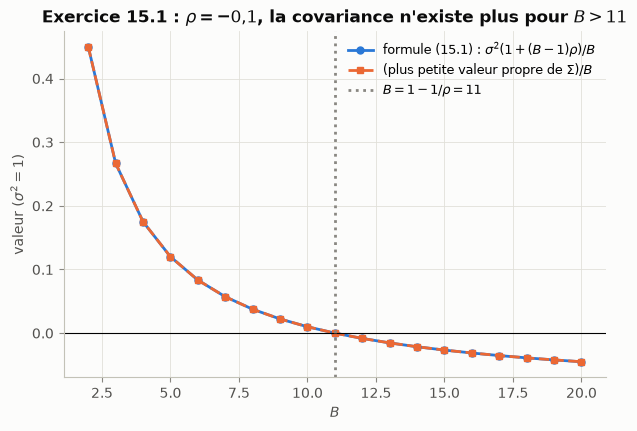

In [2]:
rho = -0.1
B_grille = np.arange(2, 21)
vp_min = [np.linalg.eigvalsh((1 - rho) * np.eye(B) + rho * np.ones((B, B))).min() for B in B_grille]
formule = rf.variance_moyenne_correlee(1.0, rho, B_grille)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(B_grille, formule, "o-", color=BLUE, label=r"formule (15.1) : $\sigma^2(1+(B-1)\rho)/B$")
ax.plot(B_grille, np.array(vp_min) / B_grille, "s--", color=ORANGE, label=r"(plus petite valeur propre de $\Sigma$)$/B$")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(1 - 1 / rho, color=GRAY, ls=":", label=r"$B=1-1/\rho=11$")
ax.set_xlabel("$B$")
ax.set_ylabel(r"valeur ($\sigma^2=1$)")
ax.set_title(r"Exercice 15.1 : $\rho=-0{,}1$, la covariance n'existe plus pour $B>11$")
ax.legend()
plt.show()

Au-delà de $B=11$, la plus petite valeur propre (et donc la formule, qui en est un
multiple pour $\mathbf 1$ dès que $\rho<0$) est négative : $\Sigma$ n'est pas une
matrice de covariance.

Le cas limite $\rho=-1/(B-1)$ est atteint : si $E_1,\dots,E_B$ sont i.i.d.
$\mathcal N(0,1)$ et $T_b=E_b-\bar E$, les $T_b$ ont la même variance, une corrélation
commune $-1/(B-1)$, et leur moyenne est identiquement nulle (variance 0, conforme à la
formule).

In [3]:
rng = np.random.RandomState(0)
B = 6
E = rng.randn(100000, B)
T = E - E.mean(axis=1, keepdims=True)
C = np.corrcoef(T.T)
print("corrélation moyenne hors diagonale : %.4f   (-1/(B-1) = %.4f)" % (C[~np.eye(B, dtype=bool)].mean(), -1 / (B - 1)))
print("variance de la moyenne : %.6f   formule : %.6f" % (T.mean(axis=1).var(), abs(rf.variance_moyenne_correlee(T.var(0).mean(), -1 / (B - 1), B))))

corrélation moyenne hors diagonale : -0.2000   (-1/(B-1) = -0.2000)
variance de la moyenne : 0.000000   formule : 0.000000


> **À retenir.** $\operatorname{Var}(\bar T)=\rho\sigma^2+(1-\rho)\sigma^2/B$ s'obtient par
> bilinéarité de la covariance. Une corrélation commune négative n'est possible que si
> $\rho\ge-1/(B-1)$ ; dans ce domaine la formule reste positive. Pour les forêts, $\rho\ge0$
> en pratique et le plancher $\rho\sigma^2$ est la quantité à réduire.

## Exercice 15.2 : Erreur OOB et validation croisée à $N$ blocs

**Énoncé.** Montrer que lorsque le nombre $B$ d'échantillons bootstrap devient grand,
l'estimation OOB de l'erreur d'une forêt aléatoire tend vers son estimation par
validation croisée à $N$ blocs (*leave-one-out*), et que l'identité est exacte à la limite.

### Notations

Un échantillon bootstrap est une suite d'indices $I_1,\dots,I_N$ **i.i.d. uniformes** sur
$\{1,\dots,N\}$ ; l'arbre correspondant dépend de ces indices et d'un aléa supplémentaire
(tirage des $m$ variables), indépendant. Notons $\mathbf Z_{-i}$ l'échantillon privé de
$z_i$.

- **Prédiction OOB de $z_i$** : moyenne (ou vote) des arbres dont l'échantillon bootstrap
  ne contient pas $i$.
- **Validation croisée à $N$ blocs** : pour chaque $i$, on ajuste une forêt sur
  $\mathbf Z_{-i}$ et on prédit $y_i$ ; l'erreur CV est la moyenne des erreurs commises.

### Étape 1 : un échantillon bootstrap qui évite $i$ est un échantillon bootstrap de $\mathbf Z_{-i}$

Conditionnons par l'événement $A_i=\{I_k\neq i\ \text{pour tout }k\}$. Comme les $I_k$
sont indépendants et que $A_i=\bigcap_k\{I_k\ne i\}$, ils restent **indépendants**
conditionnellement à $A_i$, et chacun est uniforme sur $\{1,\dots,N\}\setminus\{i\}$ :
pour $j\neq i$,
$$\mathbb P(I_k=j\mid I_k\neq i)=\frac{1/N}{(N-1)/N}=\frac1{N-1}.$$
Autrement dit, conditionnellement à $A_i$, l'échantillon est **exactement** un échantillon
bootstrap de taille $N$ tiré dans $\mathbf Z_{-i}$, et l'arbre construit a la loi d'un
arbre de forêt ajusté sur $\mathbf Z_{-i}$.

### Étape 2 : loi des grands nombres

Les arbres $b=1,\dots,B$ sont i.i.d. (conditionnellement aux données). Le nombre $B_i$
d'arbres pour lesquels $z_i$ est OOB suit une loi binomiale
$\mathcal B\big(B,(1-1/N)^N\big)$, donc $B_i\to\infty$ presque sûrement quand $B\to\infty$.
Ces $B_i$ arbres sont i.i.d. de la loi décrite à l'étape 1. Par la loi des grands nombres,
$$\hat f^{\rm oob}(x_i)=\frac1{B_i}\sum_{b:\,i\notin\mathbf Z^{*b}}T_b(x_i)\ \xrightarrow[B\to\infty]{}\ \mathbb E_{\Theta}\big[T(x_i;\Theta(\mathbf Z_{-i}))\big]=\hat f_{\rm rf}^{(-i)}(x_i),$$
la forêt « limite » (15.3) ajustée sur $\mathbf Z_{-i}$. C'est aussi la limite, quand son
nombre d'arbres tend vers l'infini, de la forêt ajustée sur $\mathbf Z_{-i}$ dans la
validation croisée.

### Conclusion

Pour chaque $i$, la prédiction OOB et la prédiction CV leave-one-out ont la **même
limite** ; l'erreur étant une moyenne finie ($N$ termes) de fonctions continues de ces
prédictions (pour l'erreur quadratique ; pour le vote majoritaire, hors cas d'égalité
exacte à $1/2$), les deux estimations d'erreur ont la même limite : l'identité est exacte
quand $B\to\infty$.

> **Remarque.** Pour une égalité exacte, la forêt de validation croisée doit tirer des
> échantillons bootstrap de taille $N$ dans les $N-1$ observations de $\mathbf Z_{-i}$ (c'est
> ce que « voit » un arbre OOB). Avec la convention usuelle (taille $N-1$), la différence
> est minime.

### Vérification numérique

Petit problème de régression ($N=30$, $p=3$), arbres de forêt avec $m=2$ et $n_{\min}=3$.
Pour la validation croisée, nous ajustons pour chaque $i$ 1000 arbres sur des échantillons
bootstrap de taille $N$ tirés dans $\mathbf Z_{-i}$ ; pour l'OOB, une forêt de $B$ arbres
avec $B$ croissant.

In [4]:
rng = np.random.RandomState(0)
N, p_ex = 30, 3
X = rng.rand(N, p_ex)
y = np.sin(4 * X[:, 0]) + X[:, 1] + 0.3 * rng.randn(N)

t0 = time.time()
B_cv = 1000
pred_cv = np.zeros(N)
for i in range(N):
    autres = np.delete(np.arange(N), i)
    s = 0.0
    for b in range(B_cv):
        boot = rng.choice(autres, N)
        s += rf.ArbreAleatoire(m=2, nmin=3, rng=rng).fit(X[boot], y[boot]).predict(X[i:i + 1])[0]
    pred_cv[i] = s / B_cv
err_cv = np.mean((pred_cv - y) ** 2)
print("erreur CV leave-one-out : %.4f   (%.0f s)" % (err_cv, time.time() - t0))

erreur CV leave-one-out : 0.2480   (8 s)


In [5]:
t0 = time.time()
foret = rf.ForetAleatoire(B=4000, m=2, nmin=3, seed=1).fit(X, y)
P = foret.predictions_arbres(X)
oob_err = rf.erreur_oob_cumulee(P, foret.dans_sac, y, classification=False)
hors = ~foret.dans_sac
ecart = []
B_vals = np.unique(np.logspace(1, np.log10(4000), 25).astype(int))
for Bv in B_vals:
    nb = hors[:Bv].sum(0)
    ok = nb > 0
    pred_oob = (P[:Bv] * hors[:Bv]).sum(0)[ok] / nb[ok]
    ecart.append(np.mean(np.abs(pred_oob - pred_cv[ok])))
print("erreur OOB avec 4000 arbres : %.4f   (%.0f s)" % (oob_err[-1], time.time() - t0))

erreur OOB avec 4000 arbres : 0.2491   (1 s)


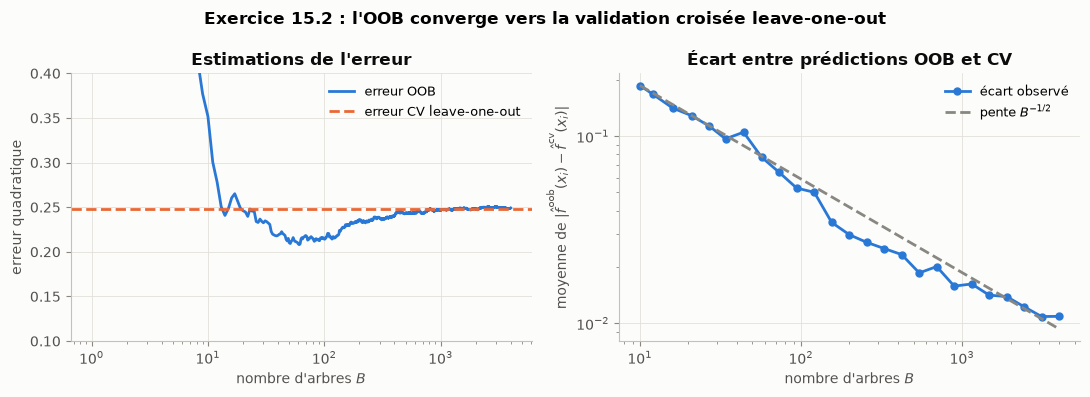

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.plot(np.arange(1, 4001), oob_err, color=BLUE, label="erreur OOB")
ax.axhline(err_cv, color=ORANGE, ls="--", label="erreur CV leave-one-out")
ax.set_xscale("log")
ax.set_ylim(0.1, 0.4)
ax.set_xlabel("nombre d'arbres $B$")
ax.set_ylabel("erreur quadratique")
ax.set_title("Estimations de l'erreur")
ax.legend()
ax = axes[1]
ax.loglog(B_vals, ecart, "o-", color=BLUE, label="écart observé")
ax.loglog(B_vals, ecart[0] * np.sqrt(B_vals[0] / B_vals), "--", color=GRAY, label=r"pente $B^{-1/2}$")
ax.set_xlabel("nombre d'arbres $B$")
ax.set_ylabel(r"moyenne de $|\hat f^{\rm oob}(x_i)-\hat f^{\rm cv}(x_i)|$")
ax.set_title("Écart entre prédictions OOB et CV")
ax.legend()
fig.suptitle("Exercice 15.2 : l'OOB converge vers la validation croisée leave-one-out", fontweight="bold")
plt.tight_layout()
plt.show()

L'écart entre prédictions OOB et CV décroît comme $B^{-1/2}$ (fluctuations de la loi des
grands nombres) jusqu'à atteindre le niveau de bruit de notre propre estimation CV
(1000 arbres par bloc) ; les deux erreurs se rejoignent.

> **À retenir.** Un échantillon bootstrap qui ne contient pas $z_i$ est un échantillon
> bootstrap de $\mathbf Z_{-i}$. L'erreur OOB est donc une validation croisée
> leave-one-out « gratuite », exacte à la limite $B\to\infty$.

## Exercice 15.3 : Le modèle de Mease et Wyner

**Énoncé.** On simule des observations binaires avec
$$\mathbb P(Y=1\mid X)=q+(1-2q)\cdot\mathbf 1\Big\{\sum_{j=1}^JX_j>J/2\Big\}\qquad(15.11)$$
où $X\sim\mathcal U[0,1]^p$, $0\le q\le\frac12$, et $J\le p$ est un entier pair fixé.
Décrire cette surface de probabilité et donner le taux d'erreur de Bayes.

### Description de la surface

La fonction $x\mapsto\mathbb P(Y=1\mid X=x)$ ne prend que **deux valeurs** :

- $1-q$ sur le demi-cube $H^+=\{x\in[0,1]^p:\ x_1+\dots+x_J>J/2\}$ ;
- $q$ sur le demi-cube complémentaire $H^-$.

C'est une fonction **en marche d'escalier** dont la discontinuité est l'hyperplan
$x_1+\dots+x_J=J/2$, qui passe par le centre $(\frac12,\dots,\frac12)$ du cube et est
orthogonal au vecteur $(1,\dots,1,0,\dots,0)$ : un hyperplan « diagonal », non parallèle
aux axes. Seules les $J$ premières variables comptent ; les $p-J$ autres sont du **bruit**.
Par symétrie ($x\mapsto\mathbf 1-x$ préserve la loi uniforme et échange $H^+$ et $H^-$ à
un ensemble de mesure nulle près), $\mathbb P(X\in H^+)=\frac12$.

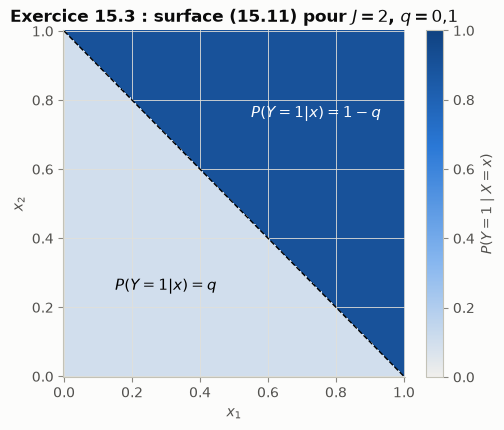

In [7]:
g = np.linspace(0, 1, 300)
G1, G2 = np.meshgrid(g, g)
q = 0.1
prob = q + (1 - 2 * q) * (G1 + G2 > 1)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.pcolormesh(G1, G2, prob, cmap=SEQ, shading="auto", vmin=0, vmax=1)
ax.plot([0, 1], [1, 0], "k--", lw=1)
ax.text(0.15, 0.25, r"$P(Y=1|x)=q$", fontsize=11)
ax.text(0.55, 0.75, r"$P(Y=1|x)=1-q$", fontsize=11, color="white")
plt.colorbar(im, ax=ax, label=r"$P(Y=1\mid X=x)$")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Exercice 15.3 : surface (15.11) pour $J=2$, $q=0{,}1$")
plt.show()

### Erreur de Bayes

Rappel (section 2.4) : pour la perte 0-1, la règle de Bayes prédit en $x$ la classe la
plus probable, et son erreur conditionnelle est
$\min\big(\mathbb P(Y=1\mid x),1-\mathbb P(Y=1\mid x)\big)$.

- Sur $H^+$, $\mathbb P(Y=1\mid x)=1-q\ge\frac12$ (car $q\le\frac12$) : on prédit 1, erreur $q$.
- Sur $H^-$, $\mathbb P(Y=1\mid x)=q\le\frac12$ : on prédit 0, erreur $q$.

L'erreur conditionnelle vaut $q$ **partout**, donc en intégrant sur la loi de $X$ :
$$\text{erreur de Bayes}=\mathbb E_X\big[\min(p(X),1-p(X))\big]=q .$$
La règle de Bayes est $\hat Y=\mathbf 1\{x_1+\dots+x_J>J/2\}$. (Pour $q=\frac12$, $Y$ est
indépendant de $X$ et toute règle a une erreur de $\frac12$.)

In [8]:
rng = np.random.RandomState(0)
for J, p_ in [(2, 7), (4, 20), (6, 50)]:
    for q in (0.05, 0.1, 0.25):
        X, y = rf.simuler_mease_wyner(200000, p_, J=J, q=q, rng=rng)
        bayes = (X[:, :J].sum(1) > J / 2).astype(int)
        print("J = %d, p = %2d, q = %.2f : erreur de la règle de Bayes simulée = %.4f" % (J, p_, q, np.mean(bayes != y)))

J = 2, p =  7, q = 0.05 : erreur de la règle de Bayes simulée = 0.0504
J = 2, p =  7, q = 0.10 : erreur de la règle de Bayes simulée = 0.1003
J = 2, p =  7, q = 0.25 : erreur de la règle de Bayes simulée = 0.2485
J = 4, p = 20, q = 0.05 : erreur de la règle de Bayes simulée = 0.0499
J = 4, p = 20, q = 0.10 : erreur de la règle de Bayes simulée = 0.0995
J = 4, p = 20, q = 0.25 : erreur de la règle de Bayes simulée = 0.2526
J = 6, p = 50, q = 0.05 : erreur de la règle de Bayes simulée = 0.0501
J = 6, p = 50, q = 0.10 : erreur de la règle de Bayes simulée = 0.0994
J = 6, p = 50, q = 0.25 : erreur de la règle de Bayes simulée = 0.2510


### Illustration : forêts et boosting face au bruit (figure 15.7, version réduite)

La figure 15.7 compare forêt ($m=\lfloor\sqrt p\rfloor$) et boosting pour $J=2$ variables
pertinentes et un nombre croissant de variables de bruit, avec $N=300$ et 500 points
test. Nous la reproduisons avec 6 simulations par configuration (au lieu de 50) et
$q=0{,}1$, à l'aide de scikit-learn (300 arbres pour la forêt ; boosting de 200 arbres à 4
feuilles, $\nu=0{,}1$).

In [9]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

configs = [5, 25, 50, 100, 150]
n_sim = 6
res = {"Forêt aléatoire": np.zeros((n_sim, len(configs))), "Boosting": np.zeros((n_sim, len(configs)))}
rng = np.random.RandomState(0)
t0 = time.time()
for k, bruit in enumerate(configs):
    p_ = 2 + bruit
    for s in range(n_sim):
        X, y = rf.simuler_mease_wyner(300, p_, J=2, q=0.1, rng=rng)
        Xt, yt = rf.simuler_mease_wyner(500, p_, J=2, q=0.1, rng=rng)
        f = RandomForestClassifier(300, max_features="sqrt", n_jobs=-1, random_state=s).fit(X, y)
        g_ = GradientBoostingClassifier(n_estimators=200, max_leaf_nodes=4, learning_rate=0.1, random_state=s).fit(X, y)
        res["Forêt aléatoire"][s, k] = np.mean(f.predict(Xt) != yt)
        res["Boosting"][s, k] = np.mean(g_.predict(Xt) != yt)
print("temps : %.0f s" % (time.time() - t0))

temps : 26 s


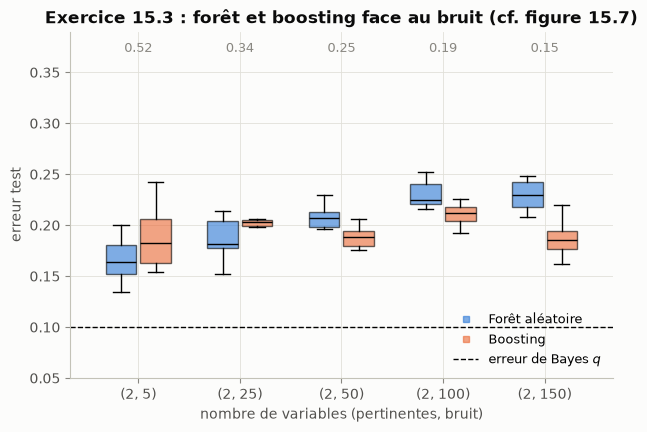

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
pos = np.arange(len(configs))
for dec, (nom, R), c in zip((-0.17, 0.17), res.items(), (BLUE, ORANGE)):
    bp = ax.boxplot(R, positions=pos + dec, widths=0.3, patch_artist=True, showfliers=False)
    for patch in bp["boxes"]:
        patch.set_facecolor(c)
        patch.set_alpha(0.6)
    for med in bp["medians"]:
        med.set_color("k")
    ax.plot([], [], "s", color=c, alpha=0.6, label=nom)
ax.axhline(0.1, color="k", ls="--", lw=1, label="erreur de Bayes $q$")
for k, bruit in enumerate(configs):
    p_ = 2 + bruit
    ax.text(k, 0.37, "%.2f" % rf.proba_variable_pertinente(p_, 2, int(np.sqrt(p_))), ha="center", fontsize=9, color=GRAY)
ax.set_xticks(pos, ["(2, %d)" % b for b in configs])
ax.set_ylim(0.05, 0.39)
ax.set_xlabel("nombre de variables (pertinentes, bruit)")
ax.set_ylabel("erreur test")
ax.set_title("Exercice 15.3 : forêt et boosting face au bruit (cf. figure 15.7)")
ax.legend(loc="lower right")
plt.show()

Les nombres gris en haut sont les probabilités qu'au moins une variable pertinente soit
candidate à une coupure. Quand elle diminue, l'erreur de la forêt augmente et l'écart se
creuse en faveur du boosting, qui choisit à chaque étape la meilleure variable parmi
toutes (avec seulement 6 simulations par configuration, la tendance reste bruitée).

> **À retenir.** La surface (15.11) vaut $q$ ou $1-q$ de part et d'autre de l'hyperplan
> diagonal $x_1+\dots+x_J=J/2$ ; l'erreur de Bayes est $q$. Les variables $X_{J+1},\dots,X_p$
> sont du bruit, qui pénalise les forêts avec petit $m$.

## Exercice 15.4 : Moyennes bootstrap : corrélation et bagging

**Énoncé.** Soient $x_1,\dots,x_n$ i.i.d. d'espérance $\mu$ et de variance $\sigma^2$, et
$\bar x^*_1,\bar x^*_2$ deux réalisations bootstrap de la moyenne empirique. Montrer que
$\operatorname{corr}(\bar x^*_1,\bar x^*_2)=\frac n{2n-1}\approx50\,\%$. En chemin, calculer
$\operatorname{Var}(\bar x^*_1)$ et la variance de la moyenne baguée $\bar x_{\rm bag}$.
Comme $\bar x$ est une statistique linéaire, le bagging ne réduit pas sa variance.

### Outils : variance et covariance conditionnelles

Pour des variables $U,V$ et une variable de conditionnement $W$ :
$$\operatorname{Var}U=\mathbb E\big[\operatorname{Var}(U\mid W)\big]+\operatorname{Var}\big(\mathbb E[U\mid W]\big),$$
$$\operatorname{Cov}(U,V)=\mathbb E\big[\operatorname{Cov}(U,V\mid W)\big]+\operatorname{Cov}\big(\mathbb E[U\mid W],\mathbb E[V\mid W]\big).$$
(On les obtient en écrivant $U-\mathbb EU=(U-\mathbb E[U\mid W])+(\mathbb E[U\mid W]-\mathbb EU)$,
en développant, et en remarquant que le terme croisé est d'espérance nulle.) Ici, on
conditionne par l'échantillon $\mathbf x=(x_1,\dots,x_n)$.

### Loi conditionnelle d'une moyenne bootstrap

$\bar x^*=\frac1n\sum_{k=1}^nx^*_k$ où les $x^*_k$ sont, sachant $\mathbf x$, i.i.d.
uniformes sur $\{x_1,\dots,x_n\}$. Chaque $x^*_k$ a donc, sachant $\mathbf x$,
- pour espérance $\frac1n\sum_ix_i=\bar x$ ;
- pour variance $\hat\sigma^2=\frac1n\sum_i(x_i-\bar x)^2$.

Par indépendance conditionnelle des $x^*_k$ :
$$\mathbb E[\bar x^*\mid\mathbf x]=\bar x,\qquad \operatorname{Var}(\bar x^*\mid\mathbf x)=\frac{\hat\sigma^2}{n}.$$

### Variance de $\bar x^*$

On rappelle que $\mathbb E\hat\sigma^2=\frac{n-1}n\sigma^2$ (biais de l'estimateur
« en $1/n$ » de la variance) et $\operatorname{Var}\bar x=\sigma^2/n$. Par la formule de
la variance totale :
$$\operatorname{Var}(\bar x^*)=\mathbb E\Big[\frac{\hat\sigma^2}n\Big]+\operatorname{Var}(\bar x)
=\frac{(n-1)\sigma^2}{n^2}+\frac{\sigma^2}n=\frac{(2n-1)\,\sigma^2}{n^2}.$$
Une moyenne bootstrap est presque **deux fois plus variable** que $\bar x$.

### Covariance et corrélation

Sachant $\mathbf x$, les deux tirages bootstrap sont indépendants, donc
$\operatorname{Cov}(\bar x^*_1,\bar x^*_2\mid\mathbf x)=0$. Par la formule de la covariance
totale :
$$\operatorname{Cov}(\bar x^*_1,\bar x^*_2)=0+\operatorname{Cov}(\bar x,\bar x)=\frac{\sigma^2}n .$$
D'où
$$\operatorname{corr}(\bar x^*_1,\bar x^*_2)=\frac{\sigma^2/n}{(2n-1)\sigma^2/n^2}=\frac n{2n-1}\ \xrightarrow[n\to\infty]{}\ \frac12 .$$

### Variance de la moyenne baguée

$\bar x_{\rm bag}=\frac1B\sum_{b=1}^B\bar x^*_b$ est une moyenne de $B$ variables de même
variance $\sigma_*^2=(2n-1)\sigma^2/n^2$ et de corrélation $\rho=n/(2n-1)$. Par (15.1) :
$$\operatorname{Var}(\bar x_{\rm bag})=\rho\sigma_*^2+\frac{1-\rho}B\sigma_*^2
=\frac{\sigma^2}n+\frac{n-1}{2n-1}\cdot\frac{(2n-1)\sigma^2}{n^2B}
=\frac{\sigma^2}n+\frac{(n-1)\sigma^2}{n^2B}.$$
Elle est **supérieure ou égale** à $\operatorname{Var}\bar x=\sigma^2/n$, avec égalité quand
$B\to\infty$ (alors $\bar x_{\rm bag}\to\mathbb E[\bar x^*\mid\mathbf x]=\bar x$). Le bagging
ne fait que reproduire $\bar x$, avec du bruit en plus.

> **Intuition.** Bagger revient à remplacer une statistique $\hat\theta(\mathbf x)$ par
> $\mathbb E[\hat\theta(\mathbf x^*)\mid\mathbf x]$. Pour une statistique **linéaire** en
> les observations, cette espérance redonne exactement $\hat\theta(\mathbf x)$ : rien n'est
> lissé. Pour un arbre, fonction très non linéaire et discontinue des données, la moyenne
> bootstrap lisse effectivement et réduit la variance.

### Vérification par simulation

In [11]:
rng = np.random.RandomState(0)
n_rep, sigma = 40000, 2.0
res_n = []
for n in (2, 3, 5, 10, 30):
    x = 1.0 + sigma * rng.randn(n_rep, n)
    m1 = np.take_along_axis(x, rng.randint(0, n, (n_rep, n)), 1).mean(1)
    m2 = np.take_along_axis(x, rng.randint(0, n, (n_rep, n)), 1).mean(1)
    res_n.append((n, np.corrcoef(m1, m2)[0, 1], m1.var()))
    print("n = %2d : corr simulée %.3f (théorie %.3f) ; Var(x*) simulée %.3f (théorie %.3f)"
          % (n, res_n[-1][1], rf.correlation_moyennes_bootstrap(n), m1.var(),
             rf.variance_moyenne_bootstrap(sigma ** 2, n)))

n =  2 : corr simulée 0.668 (théorie 0.667) ; Var(x*) simulée 2.993 (théorie 3.000)
n =  3 : corr simulée 0.593 (théorie 0.600) ; Var(x*) simulée 2.198 (théorie 2.222)
n =  5 : corr simulée 0.551 (théorie 0.556) ; Var(x*) simulée 1.430 (théorie 1.440)
n = 10 : corr simulée 0.526 (théorie 0.526) ; Var(x*) simulée 0.757 (théorie 0.760)
n = 30 : corr simulée 0.509 (théorie 0.508) ; Var(x*) simulée 0.264 (théorie 0.262)


In [12]:
n, B = 10, 5
x = 1.0 + sigma * rng.randn(n_rep, n)
boots = np.stack([np.take_along_axis(x, rng.randint(0, n, (n_rep, n)), 1).mean(1) for _ in range(B)], 1)
x_bag = boots.mean(1)
print("n = %d, B = %d : Var(x_bag) simulée %.4f, théorie %.4f ; Var(x barre) = %.4f"
      % (n, B, x_bag.var(), sigma ** 2 / n + (n - 1) * sigma ** 2 / (n ** 2 * B), x.mean(1).var()))

n = 10, B = 5 : Var(x_bag) simulée 0.4688, théorie 0.4720 ; Var(x barre) = 0.3952


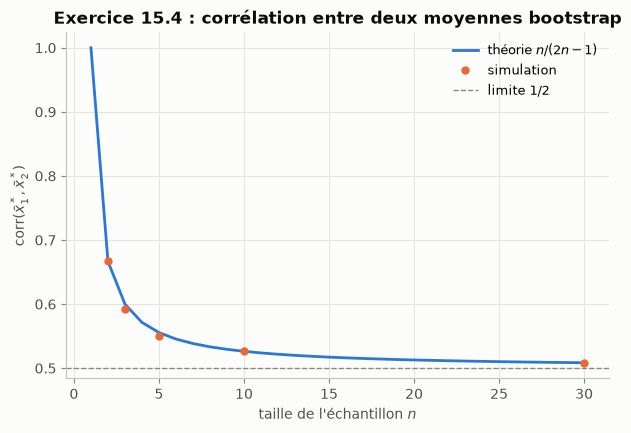

In [13]:
n_grille = np.arange(1, 31)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(n_grille, rf.correlation_moyennes_bootstrap(n_grille), color=BLUE, label=r"théorie $n/(2n-1)$")
ax.plot([r[0] for r in res_n], [r[1] for r in res_n], "o", color=ORANGE, label="simulation")
ax.axhline(0.5, color=GRAY, ls="--", lw=1, label="limite 1/2")
ax.set_xlabel("taille de l'échantillon $n$")
ax.set_ylabel(r"corr$(\bar x^*_1,\bar x^*_2)$")
ax.set_title("Exercice 15.4 : corrélation entre deux moyennes bootstrap")
ax.legend()
plt.show()